# 02 - OLAP Analysis

This notebook performs OLAP analysis on the Washington State EV registration dataset. It answers five original research questions (Q1–Q5) and three emergent questions (EQ1, EQ2, EQ4) from clustering. All analysis uses groupby aggregations, pivot tables, and visualizations on the cleaned dataset produced by the preprocessing module.

In [1]:
# The required libraries to run the analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [2]:
# Load the cleaned vehicle-level dataset, county cluster assignments, and county features

df = pd.read_csv("outputs/results/cleaned_data.csv", low_memory=False)
county_clustered = pd.read_csv("outputs/results/county_clustered.csv")
county_features = pd.read_csv("outputs/results/county_features.csv")

print(f"Vehicle records: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"County clustered table: {county_clustered.shape[0]} counties")
print()
print("Cleaned dataset columns:")
print(df.columns.tolist())
print()
print("County clustered columns:")
print(county_clustered.columns.tolist())

Vehicle records: 271,103 rows x 15 columns
County clustered table: 246 counties

Cleaned dataset columns:
['County', 'City', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Legislative District', 'Electric Utility', 'CAFV_Category', 'EV_Type', 'Range_Category', 'EV_Era']

County clustered columns:
['County', 'Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models', 'Most_Common_Make', 'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion', 'Cluster']


EV registrations by era:
                EV_Era  Vehicle_Count  Pct
      Early EV (≤2012)           2045  0.8
Growth Era (2013-2017)          25056  9.2
Mainstream (2018-2021)          57202 21.1
        Modern (2022+)         186800 68.9


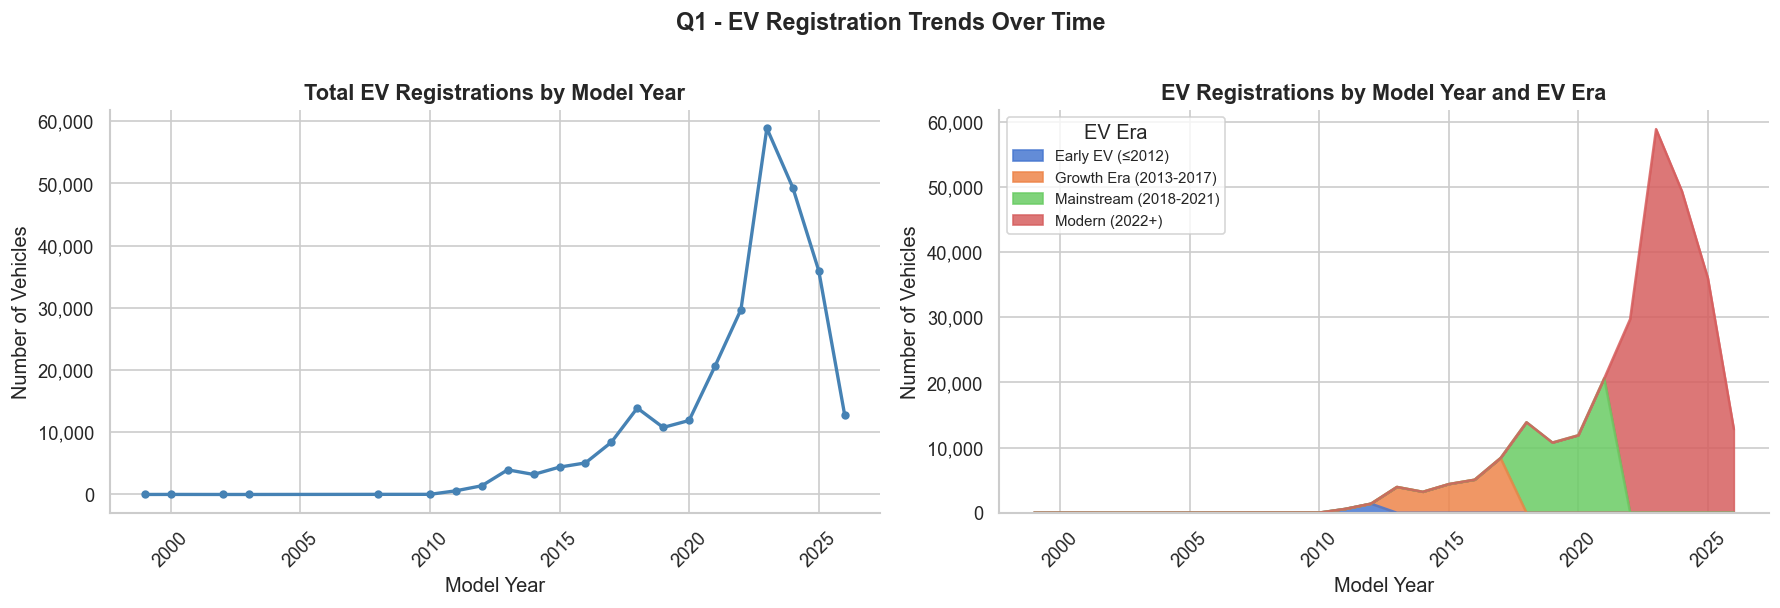

Figure saved: outputs/figures/q1_ev_registrations_over_time.png


In [3]:
# Q1 - Count EV registrations per model year and break down by EV_Era to show adoption trend over time

year_counts = (
    df.groupby("Model Year")
    .size()
    .reset_index(name="Vehicle_Count")
    .sort_values("Model Year")
)

era_year_counts = (
    df.groupby(["Model Year", "EV_Era"])
    .size()
    .reset_index(name="Vehicle_Count")
    .sort_values("Model Year")
)

era_summary = (
    df.groupby("EV_Era")
    .size()
    .reset_index(name="Vehicle_Count")
    .assign(Pct=lambda x: (x["Vehicle_Count"] / x["Vehicle_Count"].sum() * 100).round(1))
)
print("EV registrations by era:")
print(era_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    year_counts["Model Year"],
    year_counts["Vehicle_Count"],
    color="steelblue", linewidth=2, marker="o", markersize=4
)
axes[0].set_title("Total EV Registrations by Model Year", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Model Year")
axes[0].set_ylabel("Number of Vehicles")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[0].tick_params(axis="x", rotation=45)

era_pivot = (
    era_year_counts
    .pivot(index="Model Year", columns="EV_Era", values="Vehicle_Count")
    .fillna(0)
)
era_pivot.plot(
    kind="area", stacked=True, ax=axes[1],
    color=sns.color_palette("muted", n_colors=era_pivot.shape[1]), alpha=0.85
)
axes[1].set_title("EV Registrations by Model Year and EV Era", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Model Year")
axes[1].set_ylabel("Number of Vehicles")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="EV Era", loc="upper left", fontsize=9)

plt.suptitle("Q1 - EV Registration Trends Over Time", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/figures/q1_ev_registrations_over_time.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/q1_ev_registrations_over_time.png")

Top 10 manufacturers statewide:
      Make  Vehicle_Count
     TESLA         110530
 CHEVROLET          19044
    NISSAN          15955
      FORD          14937
       KIA          13617
    TOYOTA          11381
       BMW          11202
   HYUNDAI           9828
    RIVIAN           8511
VOLKSWAGEN           7367


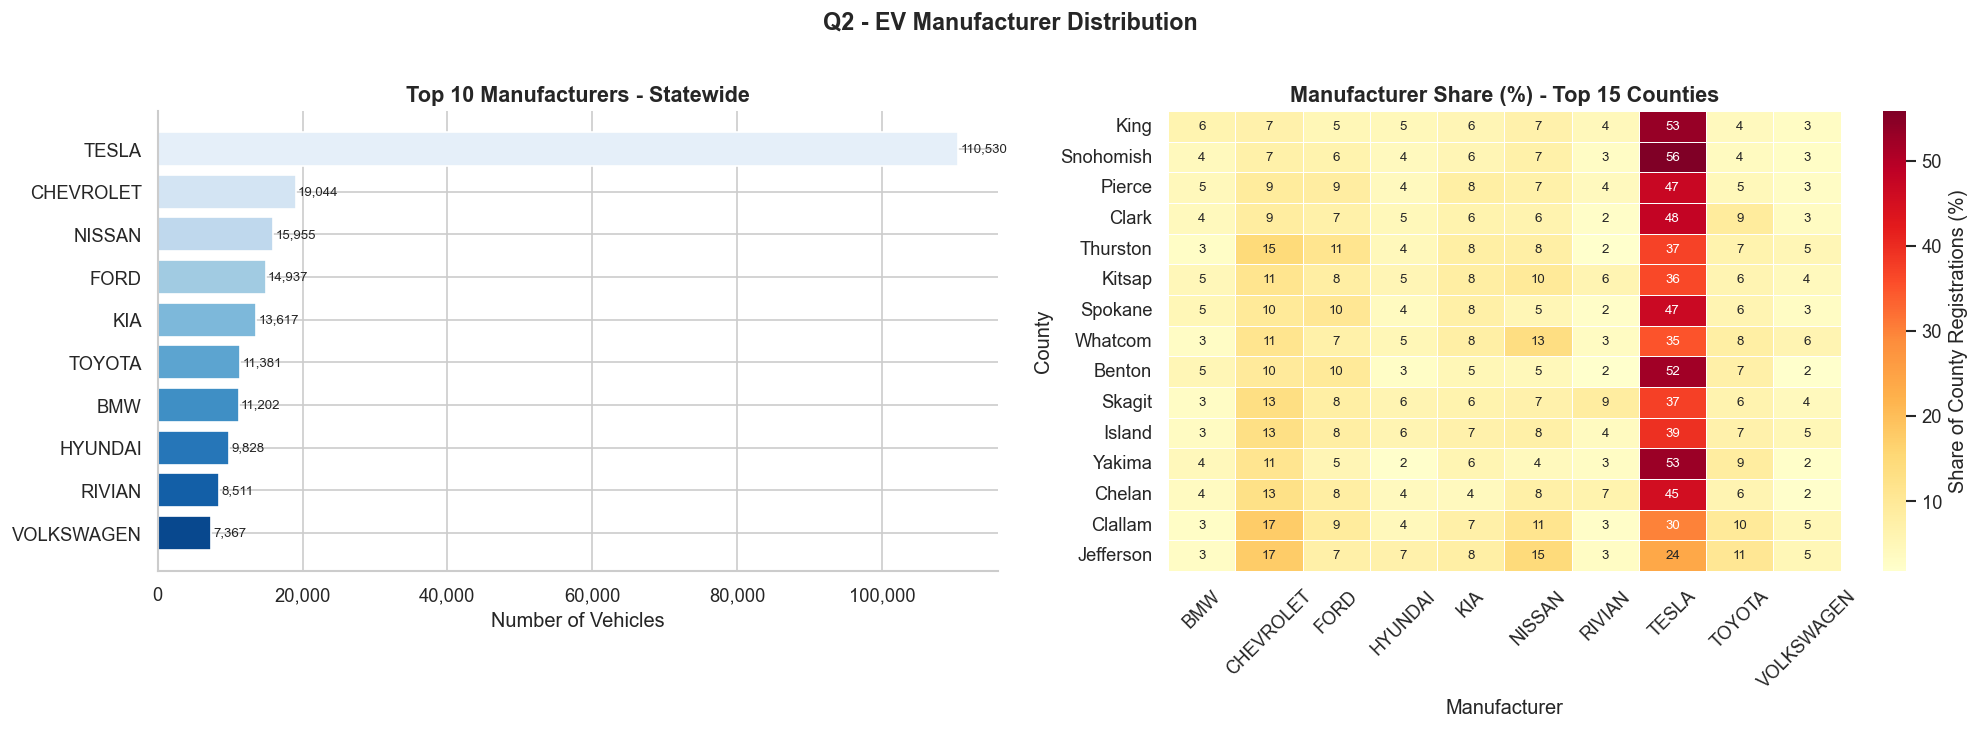

Figure saved: outputs/figures/q2_manufacturer_distribution.png


In [4]:
# Q2 - Count registrations per manufacturer statewide and show make share across top counties as a heatmap

make_counts = (
    df.groupby("Make")
    .size()
    .reset_index(name="Vehicle_Count")
    .sort_values("Vehicle_Count", ascending=False)
)
top10_makes = make_counts.head(10)
print("Top 10 manufacturers statewide:")
print(top10_makes.to_string(index=False))

top15_counties = (
    county_features.sort_values("Total_EVs", ascending=False)
    .head(15)["County"]
    .tolist()
)

df_top = df[df["County"].isin(top15_counties) & df["Make"].isin(top10_makes["Make"])]
county_make_pivot = df_top.groupby(["County", "Make"]).size().unstack(fill_value=0)
county_make_pct = county_make_pivot.div(county_make_pivot.sum(axis=1), axis=0) * 100
county_make_pct = county_make_pct.reindex(
    [c for c in top15_counties if c in county_make_pct.index]
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].barh(
    top10_makes["Make"][::-1],
    top10_makes["Vehicle_Count"][::-1],
    color=sns.color_palette("Blues_r", 10)
)
axes[0].set_title("Top 10 Manufacturers - Statewide", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Vehicles")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, val in zip(axes[0].patches, top10_makes["Vehicle_Count"][::-1]):
    axes[0].text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
                 f"{val:,}", va="center", fontsize=8)

sns.heatmap(
    county_make_pct, ax=axes[1], cmap="YlOrRd", annot=True, fmt=".0f",
    linewidths=0.4, cbar_kws={"label": "Share of County Registrations (%)"},
    annot_kws={"size": 8}
)
axes[1].set_title("Manufacturer Share (%) - Top 15 Counties", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Manufacturer")
axes[1].set_ylabel("County")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)

plt.suptitle("Q2 - EV Manufacturer Distribution", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/figures/q2_manufacturer_distribution.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/q2_manufacturer_distribution.png")

Statewide EV type breakdown:
  BEV: 216,308 vehicles (79.8%)
  PHEV: 54,795 vehicles (20.2%)


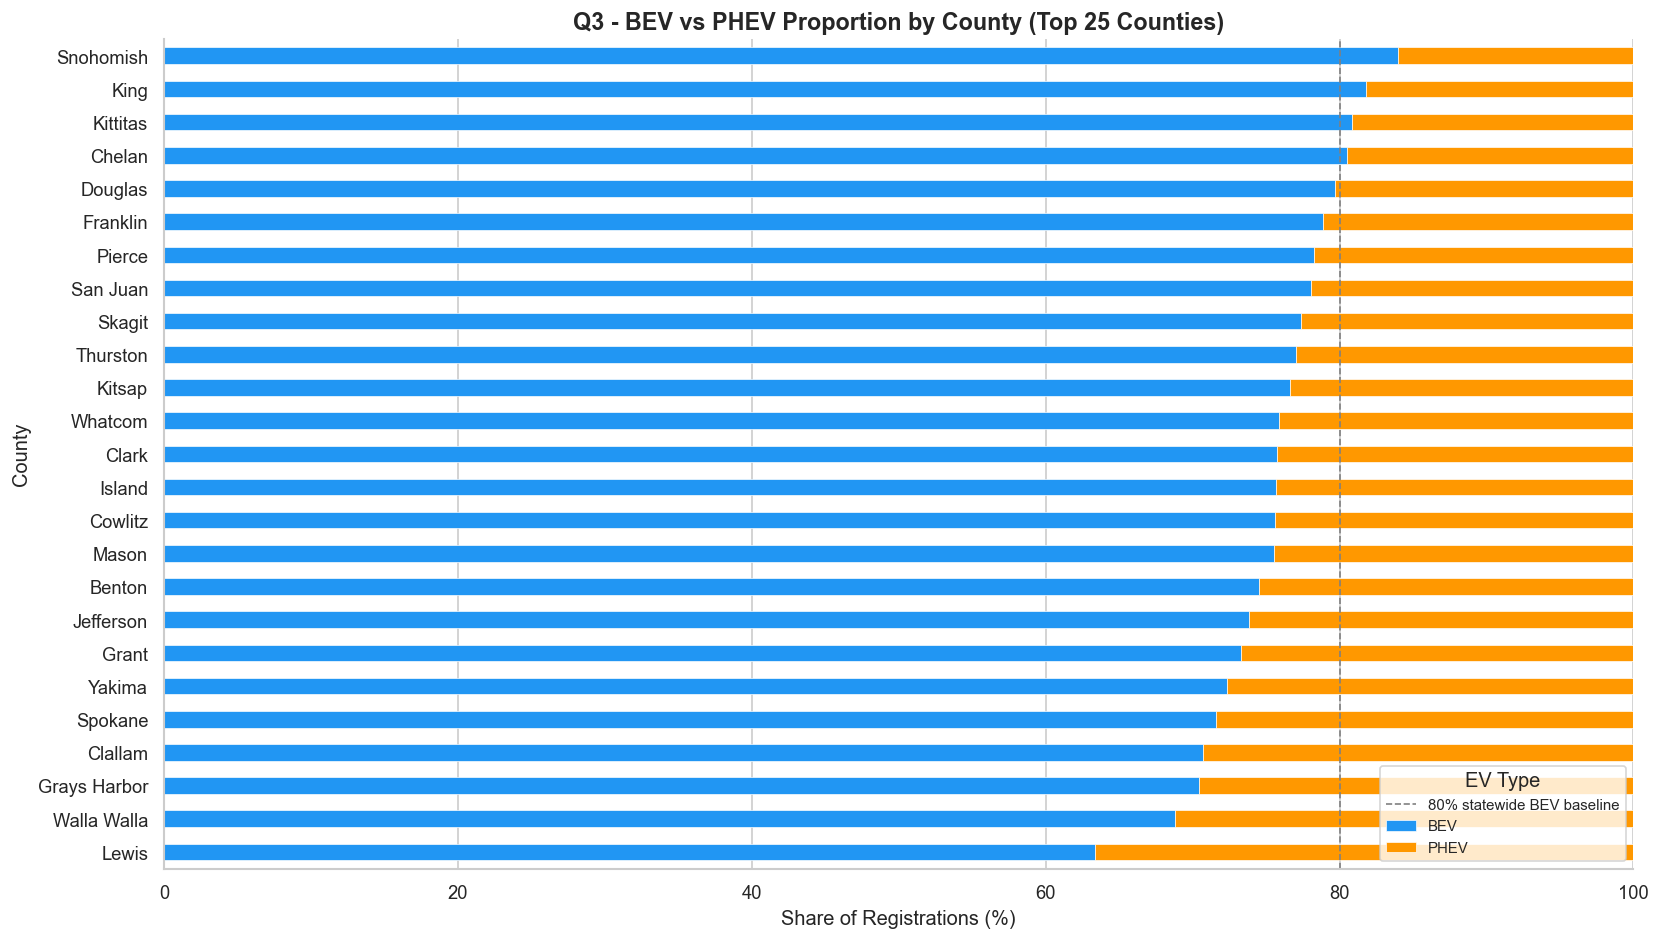

Figure saved: outputs/figures/q3_bev_phev_proportions.png


In [5]:
# Q3 - Compute BEV and PHEV share per county for the top 25 counties and plot as a stacked bar chart

top25_counties = (
    county_features.sort_values("Total_EVs", ascending=False)
    .head(25)["County"]
    .tolist()
)

county_ev_type = (
    df[df["County"].isin(top25_counties)]
    .groupby(["County", "EV_Type"])
    .size()
    .unstack(fill_value=0)
)
county_ev_pct = county_ev_type.div(county_ev_type.sum(axis=1), axis=0) * 100
county_ev_pct = county_ev_pct.sort_values("BEV", ascending=True)

statewide = df["EV_Type"].value_counts()
statewide_pct = statewide / statewide.sum() * 100
print("Statewide EV type breakdown:")
for t, pct in statewide_pct.items():
    print(f"  {t}: {statewide[t]:,} vehicles ({pct:.1f}%)")

fig, ax = plt.subplots(figsize=(14, 8))

county_ev_pct.plot(
    kind="barh", stacked=True, ax=ax,
    color=["#2196F3", "#FF9800"], edgecolor="white", linewidth=0.4
)
ax.set_title("Q3 - BEV vs PHEV Proportion by County (Top 25 Counties)", fontsize=14, fontweight="bold")
ax.set_xlabel("Share of Registrations (%)")
ax.set_ylabel("County")
ax.axvline(x=80, color="gray", linestyle="--", linewidth=1, label="80% statewide BEV baseline")
ax.legend(title="EV Type", loc="lower right", fontsize=9)
ax.set_xlim(0, 100)

plt.tight_layout()
plt.savefig("outputs/figures/q3_bev_phev_proportions.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/q3_bev_phev_proportions.png")

Electric range statistics by CAFV category:
                Count  Median   Mean  Max
CAFV_Category                            
Eligible        76205    87.0  135.3  337
Not Eligible    24089    21.0   20.7   29
Unknown        170809     0.0    0.0    0


/var/folders/c5/sg761v556rj4q__1mdbdcfs80000gn/T/ipykernel_6977/1338322753.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/c5/sg761v556rj4q__1mdbdcfs80000gn/T/ipykernel_6977/1338322753.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


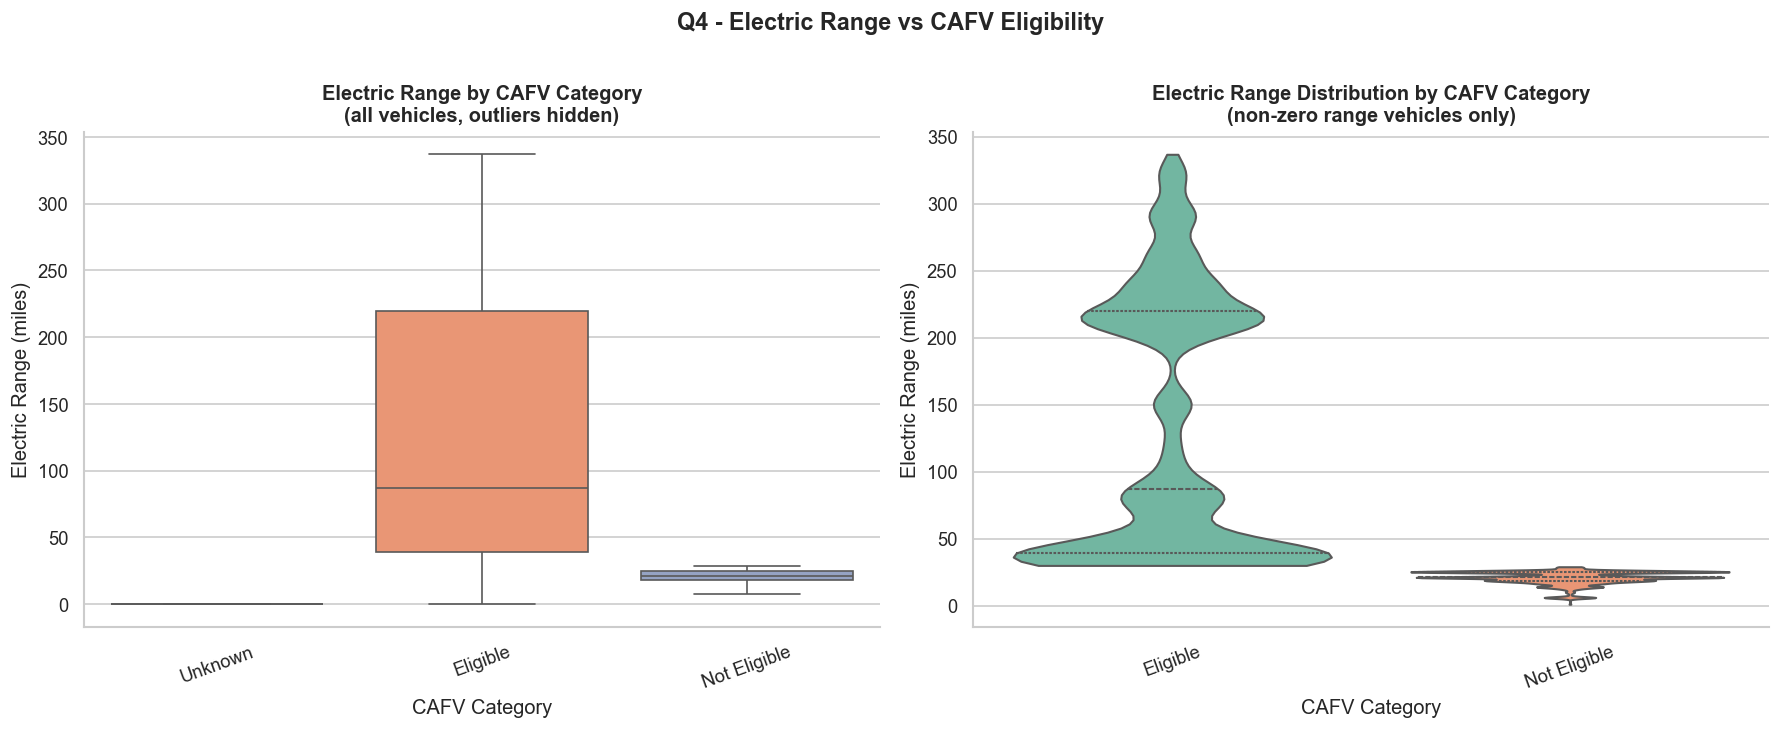

Figure saved: outputs/figures/q4_range_vs_cafv.png


In [6]:
# Q4 - Compare electric range distributions across CAFV eligibility categories using box and violin plots
# PHEVs record 0 electric range in registration databases - this is not a data error

cafv_order = df["CAFV_Category"].value_counts().index.tolist()

cafv_summary = (
    df.groupby("CAFV_Category")["Electric Range"]
    .agg(Count="count", Median="median", Mean="mean", Max="max")
    .round(1)
)
print("Electric range statistics by CAFV category:")
print(cafv_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=df, x="CAFV_Category", y="Electric Range",
    order=cafv_order, palette="Set2", ax=axes[0], showfliers=False
)
axes[0].set_title("Electric Range by CAFV Category\n(all vehicles, outliers hidden)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("CAFV Category")
axes[0].set_ylabel("Electric Range (miles)")
axes[0].tick_params(axis="x", rotation=20)

df_nonzero = df[df["Electric Range"] > 0]
sns.violinplot(
    data=df_nonzero, x="CAFV_Category", y="Electric Range",
    order=[c for c in cafv_order if c in df_nonzero["CAFV_Category"].values],
    palette="Set2", ax=axes[1], inner="quartile", cut=0
)
axes[1].set_title("Electric Range Distribution by CAFV Category\n(non-zero range vehicles only)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("CAFV Category")
axes[1].set_ylabel("Electric Range (miles)")
axes[1].tick_params(axis="x", rotation=20)

plt.suptitle("Q4 - Electric Range vs CAFV Eligibility", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/figures/q4_range_vs_cafv.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/q4_range_vs_cafv.png")

Top 20 electric utilities by EV registration count:
                                                                     Electric Utility  Vehicle_Count
                                        PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)          96306
                                                               PUGET SOUND ENERGY INC          56993
                                         CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA)          45221
                     BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLARK COUNTY - (WA)          16282
      BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY          12315
                                   PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY           6287
           BONNEVILLE POWER ADMINISTRATION||AVISTA CORP||INLAND POWER & LIGHT COMPANY           4670
                           BONNEVILLE POWER ADMINISTRATION||PUD 1 OF SNOHOMISH COUNTY           2575
                                       

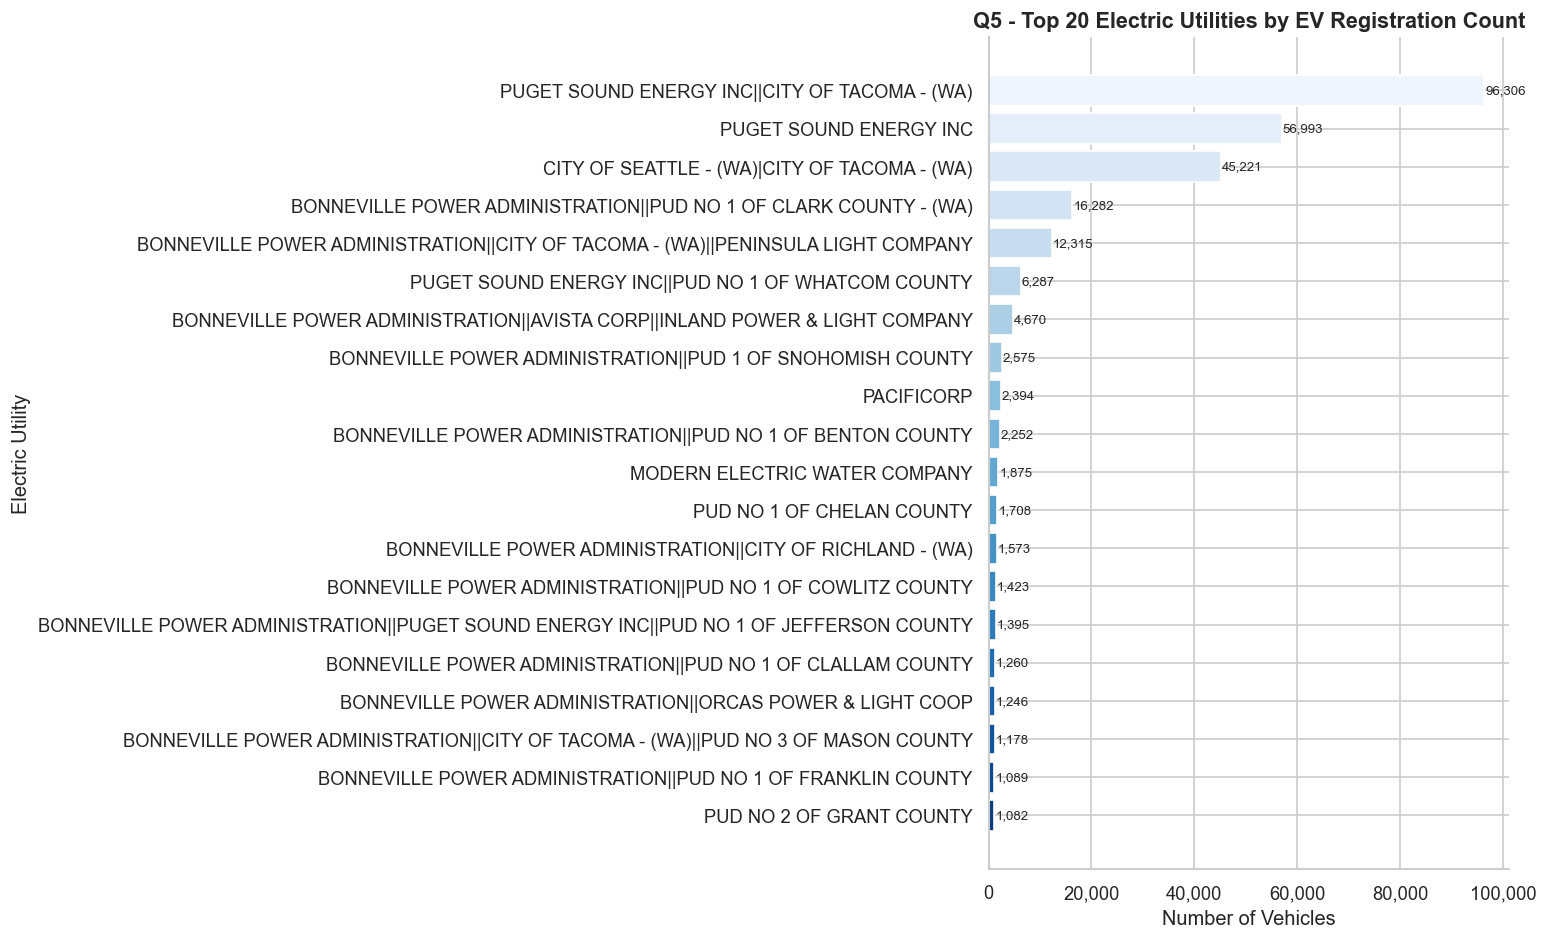

Figure saved: outputs/figures/q5_utility_ev_counts.png


In [7]:
# Q5 - Count EV registrations per electric utility and rank the top 20 utilities by vehicles served

utility_counts = (
    df.groupby("Electric Utility")
    .size()
    .reset_index(name="Vehicle_Count")
    .sort_values("Vehicle_Count", ascending=False)
)
utility_counts = utility_counts[utility_counts["Electric Utility"] != "Unknown"]
top20_utilities = utility_counts.head(20)

print("Top 20 electric utilities by EV registration count:")
print(top20_utilities.to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    top20_utilities["Electric Utility"][::-1],
    top20_utilities["Vehicle_Count"][::-1],
    color=sns.color_palette("Blues_r", n_colors=len(top20_utilities))
)
ax.set_title("Q5 - Top 20 Electric Utilities by EV Registration Count", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Vehicles")
ax.set_ylabel("Electric Utility")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar in bars:
    ax.text(bar.get_width() + 200, bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("outputs/figures/q5_utility_ev_counts.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/q5_utility_ev_counts.png")

Cluster 1 contains 59 PHEV-dominant counties.

         County  Total_EVs  PHEV_Proportion  BEV_Proportion  Avg_Electric_Range
        Alachua          1           1.0000          0.0000               21.00
    San Joaquin          1           1.0000          0.0000               25.00
         Oldham          1           1.0000          0.0000               33.00
          Otero          1           1.0000          0.0000               25.00
         Monroe          1           1.0000          0.0000               21.00
      Penobscot          1           1.0000          0.0000                6.00
         Platte          1           1.0000          0.0000               18.00
  Prince George          1           1.0000          0.0000               21.00
       Hennepin          1           1.0000          0.0000               15.00
           Guam          1           1.0000          0.0000               26.00
        Saginaw          1           1.0000          0.0000              

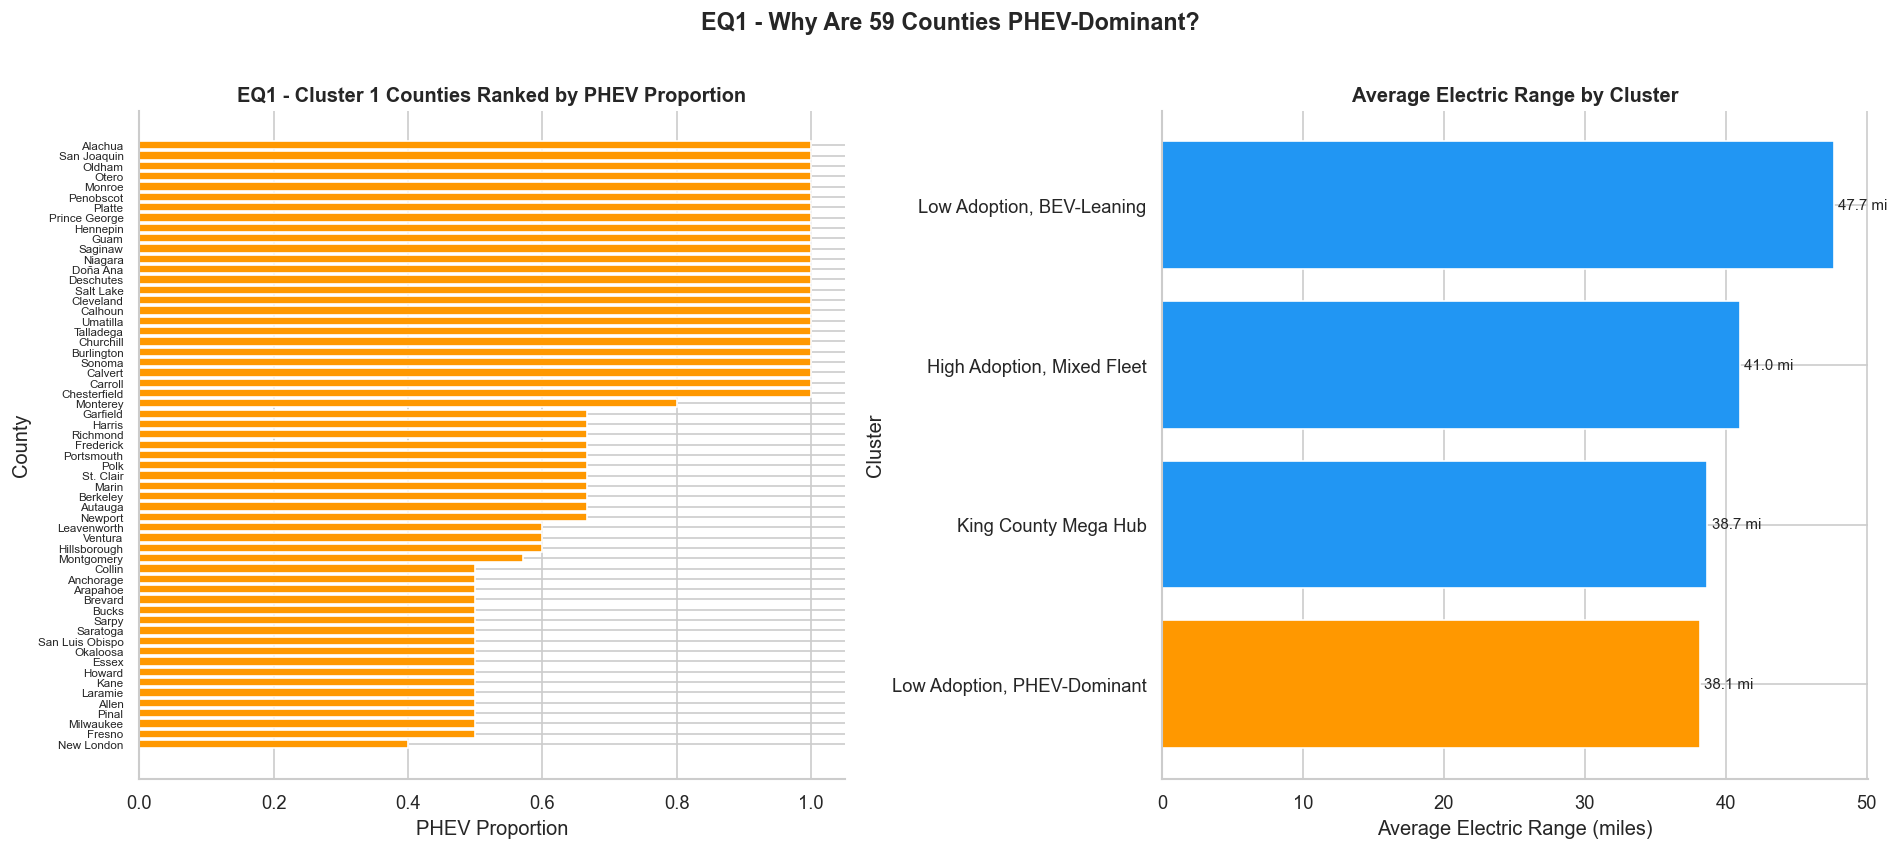

Figure saved: outputs/figures/eq1_phev_dominant_counties.png


In [9]:
# EQ1 - Identify the 59 PHEV-dominant Cluster 1 counties and compare average electric range
# across all clusters to explain why Cluster 1 has the lowest range

cluster_label_map = {
    0: "Low Adoption, BEV-Leaning",
    1: "Low Adoption, PHEV-Dominant",
    2: "High Adoption, Mixed Fleet",
    3: "King County Mega Hub"
}

county_cluster_lookup = county_clustered[["County", "Cluster"]].copy()
county_cluster_lookup["Cluster_Label"] = county_cluster_lookup["Cluster"].map(cluster_label_map)

# Extract Cluster 1 counties with their feature values for display
cluster1 = (
    county_clustered[county_clustered["Cluster"] == 1]
    .sort_values("PHEV_Proportion", ascending=False)
    .reset_index(drop=True)
)
print(f"Cluster 1 contains {len(cluster1)} PHEV-dominant counties.")
print()
print(cluster1[["County", "Total_EVs", "PHEV_Proportion", "BEV_Proportion", "Avg_Electric_Range"]].to_string(index=False))

# Merge cluster labels onto vehicle-level data for the range comparison
df_with_cluster = df.merge(county_cluster_lookup, on="County", how="left")
cluster_range = (
    df_with_cluster.dropna(subset=["Cluster"])
    .groupby("Cluster_Label")["Electric Range"]
    .mean()
    .reset_index(name="Avg_Range")
    .sort_values("Avg_Range")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left panel: ranked bar chart of Cluster 1 counties by PHEV proportion
axes[0].barh(
    cluster1["County"][::-1],
    cluster1["PHEV_Proportion"][::-1],
    color="#FF9800"
)
axes[0].set_title("EQ1 - Cluster 1 Counties Ranked by PHEV Proportion", fontsize=12, fontweight="bold")
axes[0].set_xlabel("PHEV Proportion")
axes[0].set_ylabel("County")
axes[0].tick_params(axis="y", labelsize=7)

# Right panel: average electric range across all clusters
bar_colors = ["#FF9800" if "PHEV" in lbl else "#2196F3" for lbl in cluster_range["Cluster_Label"]]
axes[1].barh(cluster_range["Cluster_Label"], cluster_range["Avg_Range"], color=bar_colors)
axes[1].set_title("Average Electric Range by Cluster", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Average Electric Range (miles)")
axes[1].set_ylabel("Cluster")
for bar in axes[1].patches:
    axes[1].text(
        bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f} mi", va="center", fontsize=9
    )

plt.suptitle("EQ1 - Why Are 59 Counties PHEV-Dominant?", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/figures/eq1_phev_dominant_counties.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/eq1_phev_dominant_counties.png")

Cluster 2 - High Adoption, Mixed Fleet (30 counties):
      County  Total_EVs  BEV_Proportion  PHEV_Proportion  Unique_Makes  Unique_Models  Avg_Model_Year
   Snohomish      33766          0.8398           0.1602            40            168         2022.18
      Pierce      22238          0.7824           0.2176            38            163         2021.95
       Clark      16694          0.7576           0.2424            40            162         2021.91
    Thurston       9911          0.7705           0.2295            37            144         2021.65
      Kitsap       9116          0.7666           0.2334            37            147         2021.72
     Spokane       7652          0.7162           0.2838            38            143         2021.94
     Whatcom       6664          0.7586           0.2414            40            147         2021.33
      Benton       3827          0.7452           0.2548            38            136         2021.69
      Skagit       3194     

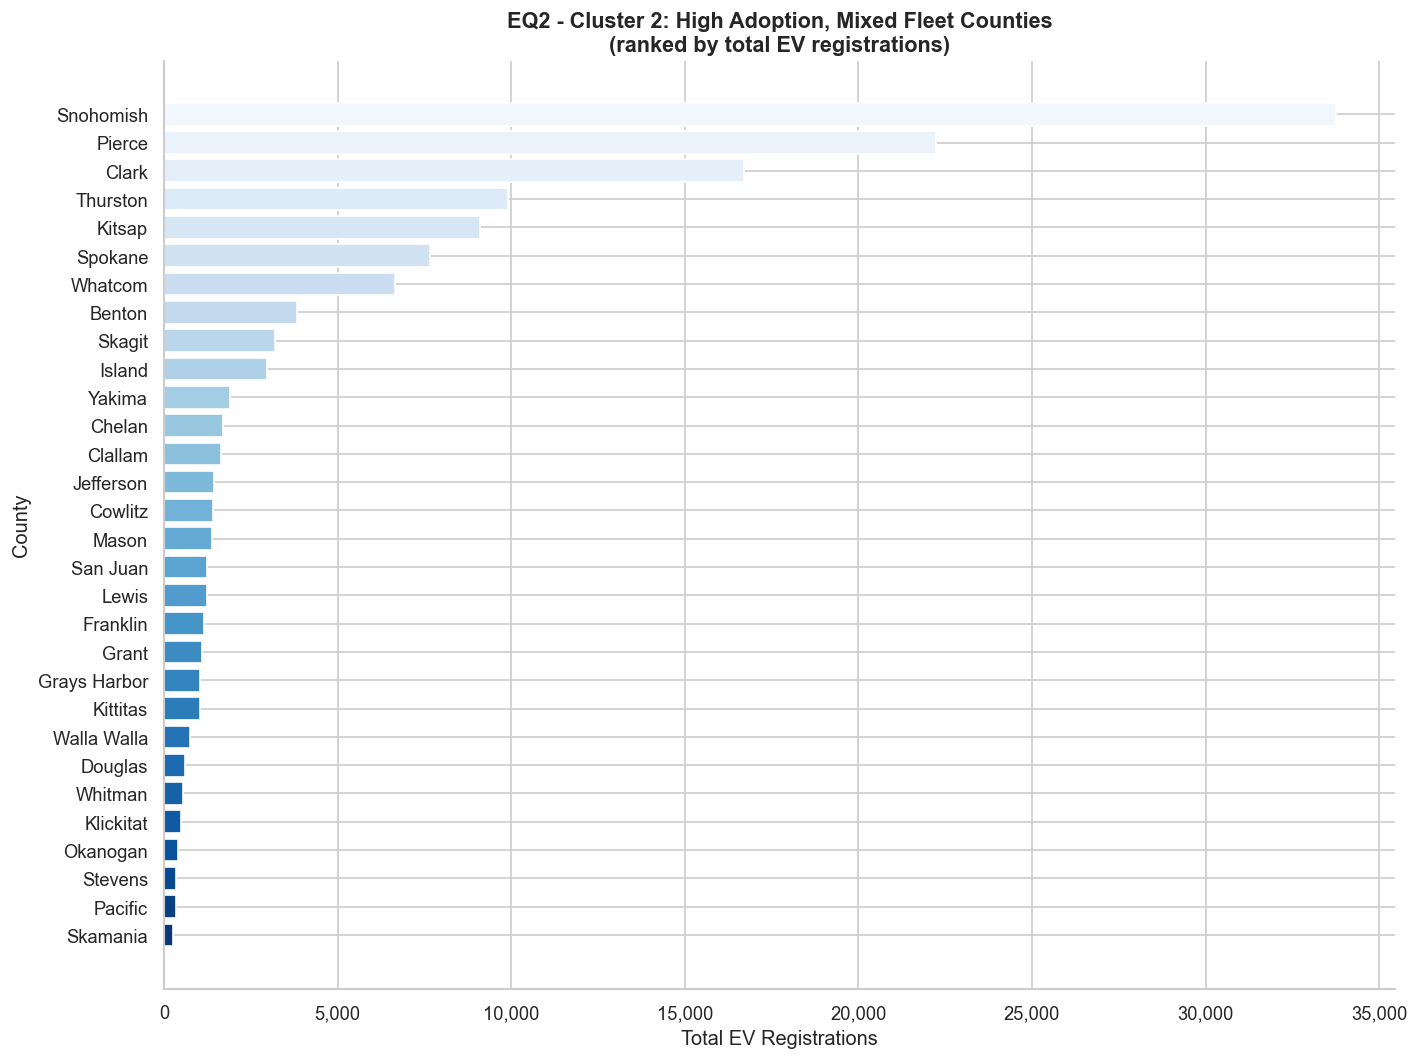

Figure saved: outputs/figures/eq2_cluster2_counties.png


In [10]:
# EQ2 - List all 30 Cluster 2 counties with their key metrics and rank them by total EV count

cluster2 = (
    county_clustered[county_clustered["Cluster"] == 2]
    .sort_values("Total_EVs", ascending=False)
    .reset_index(drop=True)
)

display_cols = [c for c in ["County", "Total_EVs", "BEV_Proportion", "PHEV_Proportion",
                             "Unique_Makes", "Unique_Models", "Avg_Model_Year"]
                if c in cluster2.columns]

print(f"Cluster 2 - High Adoption, Mixed Fleet ({len(cluster2)} counties):")
print(cluster2[display_cols].to_string(index=False))
print()
print(f"Total EVs across Cluster 2: {cluster2['Total_EVs'].sum():,.0f}")
print(f"Average Total_EVs per county: {cluster2['Total_EVs'].mean():,.1f}")

cluster2[display_cols].to_csv("outputs/results/cluster2_counties.csv", index=False)
print("Results saved: outputs/results/cluster2_counties.csv")

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    cluster2["County"][::-1],
    cluster2["Total_EVs"][::-1],
    color=sns.color_palette("Blues_r", n_colors=len(cluster2))
)
ax.set_title(
    "EQ2 - Cluster 2: High Adoption, Mixed Fleet Counties\n(ranked by total EV registrations)",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Total EV Registrations")
ax.set_ylabel("County")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.savefig("outputs/figures/eq2_cluster2_counties.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/eq2_cluster2_counties.png")

Mean Avg_Model_Year per cluster:
 Cluster               Cluster_Label  Mean_Avg_Model_Year
       0   Low Adoption, BEV-Leaning          2021.842179
       1 Low Adoption, PHEV-Dominant          2021.231186
       2  High Adoption, Mixed Fleet          2021.622667
       3        King County Mega Hub          2022.150000


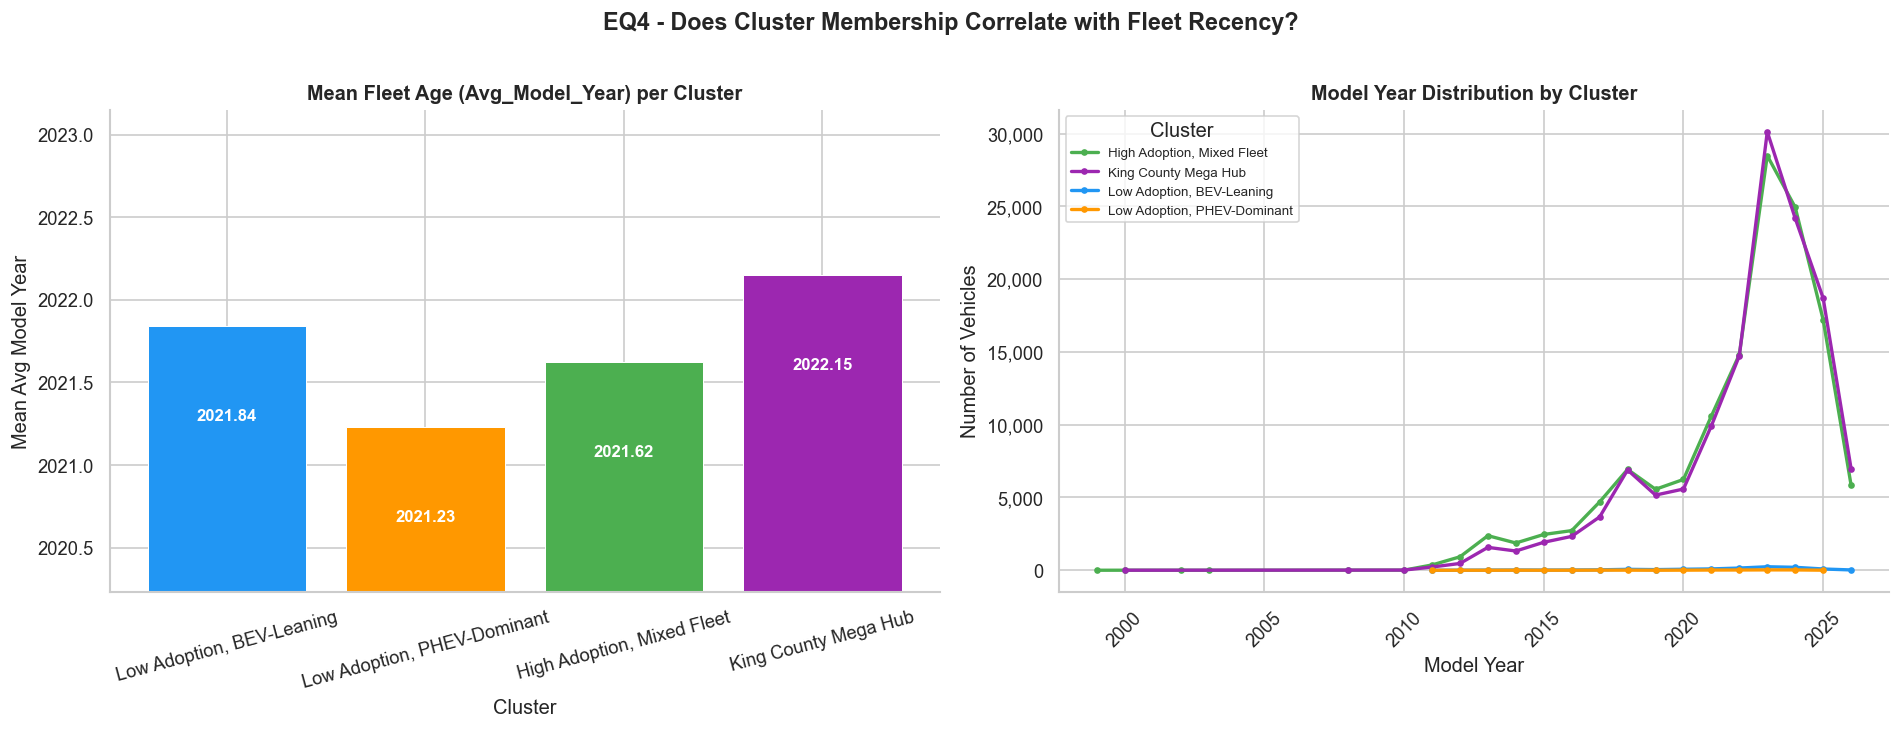

Figure saved: outputs/figures/eq4_cluster_fleet_recency.png


In [11]:
# EQ4 - Compare mean fleet age (Avg_Model_Year) across clusters and plot model year distributions
# to determine whether higher adoption clusters have newer fleets

cluster_recency = (
    county_clustered.groupby("Cluster")["Avg_Model_Year"]
    .mean()
    .reset_index()
    .rename(columns={"Avg_Model_Year": "Mean_Avg_Model_Year"})
)
cluster_recency["Cluster_Label"] = cluster_recency["Cluster"].map(cluster_label_map)

print("Mean Avg_Model_Year per cluster:")
print(cluster_recency[["Cluster", "Cluster_Label", "Mean_Avg_Model_Year"]].to_string(index=False))

cluster_year_dist = (
    df_with_cluster.dropna(subset=["Cluster"])
    .groupby(["Cluster_Label", "Model Year"])
    .size()
    .reset_index(name="Count")
)

color_map = {
    "Low Adoption, BEV-Leaning":   "#2196F3",
    "Low Adoption, PHEV-Dominant": "#FF9800",
    "High Adoption, Mixed Fleet":  "#4CAF50",
    "King County Mega Hub":        "#9C27B0"
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bar_colors = [color_map.get(lbl, "#607D8B") for lbl in cluster_recency["Cluster_Label"]]
bars = axes[0].bar(
    cluster_recency["Cluster_Label"],
    cluster_recency["Mean_Avg_Model_Year"],
    color=bar_colors, edgecolor="white", linewidth=0.6
)
for bar in bars:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() - 0.5,
        f"{bar.get_height():.2f}", ha="center", va="top",
        fontsize=10, color="white", fontweight="bold"
    )
axes[0].set_title("Mean Fleet Age (Avg_Model_Year) per Cluster", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Mean Avg Model Year")
axes[0].set_ylim(
    cluster_recency["Mean_Avg_Model_Year"].min() - 1,
    cluster_recency["Mean_Avg_Model_Year"].max() + 1
)
axes[0].tick_params(axis="x", rotation=15)

for label, grp in cluster_year_dist.groupby("Cluster_Label"):
    axes[1].plot(
        grp["Model Year"], grp["Count"],
        label=label, color=color_map.get(label, "#607D8B"),
        linewidth=2, marker="o", markersize=3
    )
axes[1].set_title("Model Year Distribution by Cluster", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Model Year")
axes[1].set_ylabel("Number of Vehicles")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[1].legend(title="Cluster", fontsize=8, loc="upper left")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("EQ4 - Does Cluster Membership Correlate with Fleet Recency?",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/figures/eq4_cluster_fleet_recency.png", bbox_inches="tight")
plt.show()
print("Figure saved: outputs/figures/eq4_cluster_fleet_recency.png")

In [1]:
# Final findings summary for the OLAP analysis module
print("=" * 60)
print("OLAP ANALYSIS — KEY FINDINGS SUMMARY")
print("=" * 60)

print("""
Q1 — EV Registration Trends Over Time:
  - Modern Era (2022+) accounts for 68.9% of all 271,103
    registrations despite being only 3-4 years of production.
  - EV adoption is accelerating, not gradual.
  - Apparent drop at 2025-2026 is a partial-year registration
    lag, not a real decline.

Q2 — Manufacturer Distribution:
  - Tesla dominates with 110,530 registrations — nearly 6x
    second-place Chevrolet (19,044).
  - Rivian already ranks #9 statewide, signaling rapid growth
    of direct-to-consumer brands.
  - Tesla share exceeds 40% in most top 15 counties.

Q3 — BEV vs PHEV Proportions by County:
  - Statewide split: 79.8% BEV vs 20.2% PHEV.
  - No top-25 county is majority PHEV — BEV preference is
    universal across high-adoption areas.
  - Lewis and Walla Walla are the most PHEV-heavy among
    the top 25 counties.

Q4 — Electric Range vs CAFV Eligibility:
  - CAFV-Eligible vehicles: median 87 mi, mean 135 mi.
  - Not Eligible vehicles: median 21 mi (older short-range BEVs).
  - Unknown category: median 0 mi — these are PHEVs that record
    0 electric range by Washington DOL convention, not a data error.
  - BEV range is bimodal: ~100 mi (older) and 250+ mi (modern).

Q5 — Electric Utility Service Areas:
  - Puget Sound Energy serves the most EVs across its two dataset
    entries (96,386 + 56,993) — more than all other utilities combined.
  - Double-pipe names (e.g. PUGET SOUND ENERGY INC||PSE) indicate
    shared service territories, not formatting errors.

EQ1 — Why Are 59 Counties PHEV-Dominant? (Cluster 1):
  - Cluster 1 counties include out-of-state registrations:
    Alachua (FL), San Joaquin (CA), Hennepin (MN), Guam, and others.
  - These are not Washington State counties — they are out-of-state
    vehicles registered in the WA DOL dataset.
  - Their PHEV dominance and low range (avg 34.4 mi) reflects
    different regional EV adoption patterns, not a WA trend.

EQ2 — Which Counties Make Up Cluster 2 (High Adoption)?:
  - 30 Washington State counties with average 4,535 EVs per county.
  - Top 5: Snohomish (33,766), Pierce (22,238), Clark (16,694),
    Thurston (9,911), Kitsap (9,116).
  - Results saved to outputs/results/cluster2_counties.csv.

EQ4 — Does Cluster Membership Correlate with Fleet Recency?:
  - King County has the newest fleet (Avg_Model_Year = 2022.15).
  - PHEV-dominant Cluster 1 has the oldest fleet (2021.23).
  - Spread across all clusters is less than 1 year — fleet recency
    is a weak differentiator between clusters.

OUTPUT FILES:
  - outputs/figures/q1_ev_registrations_over_time.png
  - outputs/figures/q2_manufacturer_distribution.png
  - outputs/figures/q3_bev_phev_proportions.png
  - outputs/figures/q4_range_vs_cafv.png
  - outputs/figures/q5_utility_ev_counts.png
  - outputs/figures/eq1_phev_dominant_counties.png
  - outputs/figures/eq2_cluster2_counties.png
  - outputs/figures/eq4_cluster_fleet_recency.png
  - outputs/results/cluster2_counties.csv
""")
print("=" * 60)
print("Module 02 complete.")
print("=" * 60)

OLAP ANALYSIS — KEY FINDINGS SUMMARY

Q1 — EV Registration Trends Over Time:
  - Modern Era (2022+) accounts for 68.9% of all 271,103
    registrations despite being only 3-4 years of production.
  - EV adoption is accelerating, not gradual.
  - Apparent drop at 2025-2026 is a partial-year registration
    lag, not a real decline.

Q2 — Manufacturer Distribution:
  - Tesla dominates with 110,530 registrations — nearly 6x
    second-place Chevrolet (19,044).
  - Rivian already ranks #9 statewide, signaling rapid growth
    of direct-to-consumer brands.
  - Tesla share exceeds 40% in most top 15 counties.

Q3 — BEV vs PHEV Proportions by County:
  - Statewide split: 79.8% BEV vs 20.2% PHEV.
  - No top-25 county is majority PHEV — BEV preference is
    universal across high-adoption areas.
  - Lewis and Walla Walla are the most PHEV-heavy among
    the top 25 counties.

Q4 — Electric Range vs CAFV Eligibility:
  - CAFV-Eligible vehicles: median 87 mi, mean 135 mi.
  - Not Eligible vehicle